[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/neurogym/neurogym/blob/main/docs/examples/demo.ipynb)


## Exploring NeuroGym Tasks


NeuroGym is a comprehensive toolkit that allows training any network model on many established neuroscience tasks using Reinforcement Learning techniques. It includes working memory tasks, value-based decision tasks and context-dependent perceptual categorization tasks.

In this notebook we first show how to install the relevant toolbox.

We then show how to access the available tasks and their relevant information.

Finally we train a feedforward neural network (MLP policy) on the Random Dots Motion task using the A2C algorithm [Mnih et al. 2016](https://arxiv.org/abs/1602.01783) implemented in the [stable-baselines3](https://stable-baselines3.readthedocs.io/en/master/) toolbox, and plot the results.

You can easily change the code to train a network on any other available task or using a different algorithm (e.g. ACER, PPO2).


### Installation

**Google Colab:** Uncomment and execute cell below when running this notebook on google colab.

**Local:** Follow [these instructions](https://github.com/neurogym/neurogym?tab=readme-ov-file#installation) when running
this notebook locally.


In [ ]:
# ! pip install neurogym[rl]

### Import libraries


In [1]:
import warnings
warnings.filterwarnings('ignore')
import neurogym as ngym
from neurogym import info
from neurogym.utils import plotting

from IPython.display import clear_output
clear_output()

### Explore tasks


In [2]:
info.show_all_tasks()

Neurogym | 2025-07-27@00:39:02 | Available tasks:
Neurogym | 2025-07-27@00:39:02 | AntiReach-v0
Neurogym | 2025-07-27@00:39:02 | Bandit-v0
Neurogym | 2025-07-27@00:39:02 | ContextDecisionMaking-v0
Neurogym | 2025-07-27@00:39:02 | DawTwoStep-v0
Neurogym | 2025-07-27@00:39:02 | DelayComparison-v0
Neurogym | 2025-07-27@00:39:02 | DelayMatchCategory-v0
Neurogym | 2025-07-27@00:39:02 | DelayMatchSample-v0
Neurogym | 2025-07-27@00:39:02 | DelayMatchSampleDistractor1D-v0
Neurogym | 2025-07-27@00:39:02 | DelayPairedAssociation-v0
Neurogym | 2025-07-27@00:39:02 | DualDelayMatchSample-v0
Neurogym | 2025-07-27@00:39:02 | EconomicDecisionMaking-v0
Neurogym | 2025-07-27@00:39:02 | GoNogo-v0
Neurogym | 2025-07-27@00:39:02 | HierarchicalReasoning-v0
Neurogym | 2025-07-27@00:39:02 | IntervalDiscrimination-v0
Neurogym | 2025-07-27@00:39:02 | MotorTiming-v0
Neurogym | 2025-07-27@00:39:02 | MultiSensoryIntegration-v0
Neurogym | 2025-07-27@00:39:02 | Null-v0
Neurogym | 2025-07-27@00:39:02 | OneTwoThreeGo-

In [8]:
info.show_info("AntiReach-v0")

Neurogym | 2025-07-27@00:42:36 | Info for environment: AntiReach
Doc: Anti-response task.

    During the fixation period, the agent fixates on a fixation point.
    During the following stimulus period, the agent is then shown a stimulus away
    from the fixation point. Finally, the agent needs to respond in the
    opposite direction of the stimulus during the decision period.

    Args:
        anti: bool, if True, requires an anti-response. If False, requires a
            pro-response, i.e. response towards the stimulus.
    
Reference paper 
[Look away: the anti-saccade task and the voluntary control of eye movement](https://www.nature.com/articles/nrn1345)

Reward structure 
abort : -0.1
correct : 1.0
fail : 0.0

Tags: perceptual, steps action space.



### Visualize a single task


In [4]:
info.show_info("GoNogo-v0")

Neurogym | 2025-07-16@14:12:19 | Info for environment: GoNogo
Doc: Go/No-go task.

    A stimulus is shown during the stimulus period. The stimulus period is
    followed by a delay period, and then a decision period. If the stimulus is
    a Go stimulus, then the subject should choose the action Go during the
    decision period, otherwise, the subject should remain fixation.
    
Reference paper 
[Active information maintenance in working memory by a sensory cortex](https://elifesciences.org/articles/43191)

Reward structure 
abort : -0.1
correct : 1.0
fail : -0.5
miss : -0.5

Tags: delayed response, go-no-go, supervised.



<OrderEnforcing<GoNogo>>


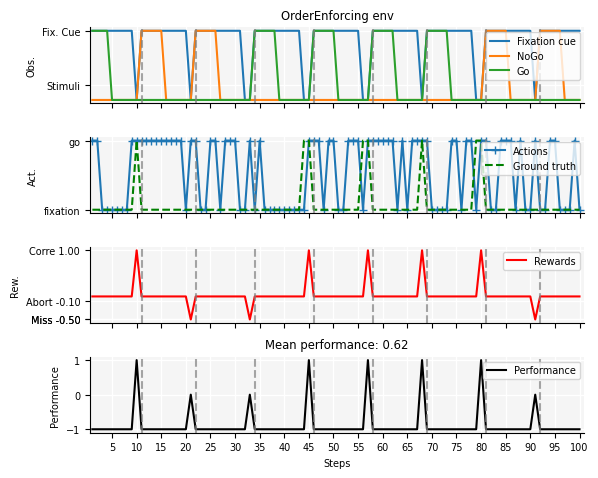

In [5]:
task = 'GoNogo-v0'
env = ngym.make(task)
print(env)
fig = plotting.plot_env(
    env,
    num_steps=100,
    # def_act=0,
    ob_traces=['Fixation cue', 'NoGo', 'Go'],
    # fig_kwargs={'figsize': (12, 12)}
    )

In [6]:
info.show_info(env)

Neurogym | 2025-07-16@14:13:32 | Info for environment: GoNogo
Doc: Go/No-go task.

    A stimulus is shown during the stimulus period. The stimulus period is
    followed by a delay period, and then a decision period. If the stimulus is
    a Go stimulus, then the subject should choose the action Go during the
    decision period, otherwise, the subject should remain fixation.
    
Reference paper 
[Active information maintenance in working memory by a sensory cortex](https://elifesciences.org/articles/43191)

Reward structure 
abort : -0.1
correct : 1.0
fail : -0.5
miss : -0.5

Tags: delayed response, go-no-go, supervised.



### Explore tags


As seen in the info of the Go-Nogo task above, each environment has a number of tags associated with it.

The complete list of tags is as follows:


In [7]:
info.show_all_tags()

Neurogym | 2025-07-16@14:13:39 | Available tags:
Neurogym | 2025-07-16@14:13:39 | go-no-go
Neurogym | 2025-07-16@14:13:39 | center-surround
Neurogym | 2025-07-16@14:13:39 | two-alternative
Neurogym | 2025-07-16@14:13:39 | context dependent
Neurogym | 2025-07-16@14:13:39 | plaid
Neurogym | 2025-07-16@14:13:39 | confidence
Neurogym | 2025-07-16@14:13:39 | working memory
Neurogym | 2025-07-16@14:13:39 | delayed response
Neurogym | 2025-07-16@14:13:39 | continuous action space
Neurogym | 2025-07-16@14:13:39 | multidimensional action space
Neurogym | 2025-07-16@14:13:39 | supervised
Neurogym | 2025-07-16@14:13:39 | steps action space
Neurogym | 2025-07-16@14:13:39 | motion
Neurogym | 2025-07-16@14:13:39 | timing
Neurogym | 2025-07-16@14:13:39 | motor
Neurogym | 2025-07-16@14:13:39 | value-based
Neurogym | 2025-07-16@14:13:39 | perceptual
Neurogym | 2025-07-16@14:13:39 | n-alternative


You can specifically list the environments associated with a given tag


In [7]:
info.show_all_tasks(tag="perceptual")

Neurogym | 2025-07-27@00:42:11 | Available tasks with tag 'perceptual':
Neurogym | 2025-07-27@00:42:11 | AntiReach-v0
Neurogym | 2025-07-27@00:42:11 | ContextDecisionMaking-v0
Neurogym | 2025-07-27@00:42:11 | DelayComparison-v0
Neurogym | 2025-07-27@00:42:11 | DelayMatchCategory-v0
Neurogym | 2025-07-27@00:42:11 | DelayMatchSample-v0
Neurogym | 2025-07-27@00:42:11 | DelayMatchSampleDistractor1D-v0
Neurogym | 2025-07-27@00:42:11 | DelayPairedAssociation-v0
Neurogym | 2025-07-27@00:42:11 | DualDelayMatchSample-v0
Neurogym | 2025-07-27@00:42:11 | EconomicDecisionMaking-v0
Neurogym | 2025-07-27@00:42:11 | HierarchicalReasoning-v0
Neurogym | 2025-07-27@00:42:11 | MultiSensoryIntegration-v0
Neurogym | 2025-07-27@00:42:11 | PerceptualDecisionMaking-v0
Neurogym | 2025-07-27@00:42:11 | PerceptualDecisionMakingDelayResponse-v0
Neurogym | 2025-07-27@00:42:11 | PostDecisionWager-v0
Neurogym | 2025-07-27@00:42:11 | ProbabilisticReasoning-v0
Neurogym | 2025-07-27@00:42:11 | PulseDecisionMaking-v0
Ne

### Explore wrappers


In [9]:
info.show_all_wrappers()

Neurogym | 2025-07-16@14:13:49 | Available wrappers:
Neurogym | 2025-07-16@14:13:49 | Monitor-v0
Neurogym | 2025-07-16@14:13:49 | Noise-v0
Neurogym | 2025-07-16@14:13:49 | PassAction-v0
Neurogym | 2025-07-16@14:13:49 | PassReward-v0
Neurogym | 2025-07-16@14:13:49 | RandomGroundTruth-v0
Neurogym | 2025-07-16@14:13:49 | ReactionTime-v0
Neurogym | 2025-07-16@14:13:49 | ScheduleAttr-v0
Neurogym | 2025-07-16@14:13:49 | ScheduleEnvs-v0
Neurogym | 2025-07-16@14:13:49 | SideBias-v0
Neurogym | 2025-07-16@14:13:49 | TrialHistoryV2-v0


In [10]:
info.show_info('Monitor-v0')


Neurogym | 2025-07-16@14:13:51 | Info for wrapper: Monitor-v0
Neurogym | 2025-07-16@14:13:51 | Logic: Saves relevant behavioral information: rewards, actions, observations, new trial, ground truth.


### Train a network

Here, we train a simple neural network on the task at hand. We use a [configuration file](./config.toml) to load the parameters for the monitor. You can refer to the [documentation](../../README.md#configuration) for more information about how to use the configuration system.


In [11]:
import numpy as np
from neurogym.wrappers import Monitor, TrialHistoryV2
from stable_baselines3.common.vec_env import DummyVecEnv
from stable_baselines3 import A2C  # ACER, PPO2
# task paremters
timing = {'fixation': ('constant', 300),
          'stimulus': ('constant', 700),
          'decision': ('constant', 300)}
kwargs = {'dt': 100, 'timing': timing}
# wrapper parameters
n_ch = 2
p = 0.8
num_blocks = 2
probs = np.array([[p, 1-p], [1-p, p]])  # repeating block

# Build the task
env = ngym.make(task, **kwargs)

# Apply the wrapper.
env = TrialHistoryV2(env, probs=probs)
env = Monitor(env, config="config.toml")

In [12]:
# the env is now wrapped automatically when passing it to the constructor
model = A2C("MlpPolicy", env, verbose=1, policy_kwargs={'net_arch': [64, 64]})
model.learn(total_timesteps=env.config.agent.training.value)
env.close()

Using cuda device
Wrapping the env with a `Monitor` wrapper
Wrapping the env in a DummyVecEnv.


### Visualize the results


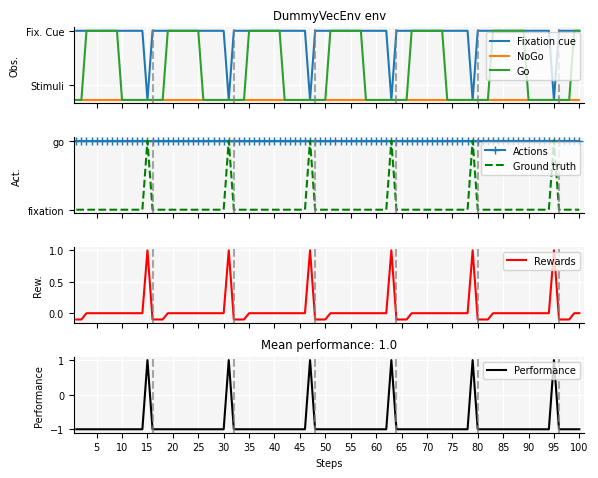

In [13]:
# Create task
env = ngym.make(task, **kwargs)
# Apply the wrapper
env = TrialHistoryV2(env, probs=probs)
env = DummyVecEnv([lambda: env])
fig = plotting.plot_env(
    env,
    num_steps=100,
    # def_act=0,
    ob_traces=['Fixation cue', 'NoGo', 'Go'],
    # fig_kwargs={'figsize': (12, 12)},
    model=model
)